In [1]:
import joblib
import numpy as np
import pandas as pd

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

import matplotlib.pyplot as plt
from pathlib import Path

# Load prepared dataset
data = joblib.load("Dataset/cycle_time_data.joblib")

df = data["df"]
yraw = data["yraw"]
TRAIN_END = data["train_end"]

# ARIMA configuration
ARIMA_WINDOW = 50
ARIMA_ORDER = (1, 0, 1)

# Results directory
OUTPUT_DIR = Path("Results/ARIMA")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", df.shape)
print("Target observations:", len(yraw))
print("Training ends at:", TRAIN_END)
print("ARIMA window:", ARIMA_WINDOW)
print("ARIMA order:", ARIMA_ORDER)

Dataset: (995, 18)
Target observations: 995
Training ends at: 400
ARIMA window: 50
ARIMA order: (1, 0, 1)


In [2]:
# First evaluation observation
i = TRAIN_END

# Previous 50 observations
history = yraw[i-ARIMA_WINDOW:i]

# Fit ARIMA model
model = ARIMA(
    history,
    order=ARIMA_ORDER
).fit()

# Forecast one observation ahead
prediction = model.forecast(steps=1)[0]

print("Historical observations:", len(history))
print("ARIMA prediction:", round(float(prediction), 2))
print("Actual processing time:", yraw[i])
print("Absolute error:", round(abs(prediction - yraw[i]), 2))

Historical observations: 50
ARIMA prediction: 73.33
Actual processing time: 87.0
Absolute error: 13.67


In [3]:
import warnings

# Store predictions
arima_results = []

# Suppress ARIMA convergence warnings
warnings.filterwarnings(
    "ignore",
    category=UserWarning
)

for i in range(TRAIN_END, len(yraw)):

    # Previous 50 actual processing times
    history = yraw[i-ARIMA_WINDOW:i]

    try:
        # Fit ARIMA on the rolling window
        model = ARIMA(
            history,
            order=ARIMA_ORDER
        ).fit()

        # Forecast one observation ahead
        prediction = float(
            model.forecast(steps=1)[0]
        )

    except Exception:
        # Fallback if ARIMA fitting fails
        prediction = float(np.mean(history))

    # Store results
    arima_results.append({
        "idx": i,
        "phase": df.loc[i, "phase"],
        "actual": float(yraw[i]),
        "predicted": prediction
    })

# Convert results to DataFrame
arima_results_df = pd.DataFrame(arima_results)

print("Total ARIMA predictions:", len(arima_results_df))

display(arima_results_df.head())

Total ARIMA predictions: 595


,idx,phase,actual,predicted
0,400,stable,87.0,73.333068
1,401,stable,120.0,70.912360
2,402,stable,54.0,76.041434
3,403,stable,31.0,66.473211
4,404,stable,93.0,63.440856


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Function to calculate evaluation metrics
def calculate_metrics(group):

    actual = group["actual"]
    predicted = group["predicted"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return pd.Series({
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })


# Calculate metrics for each phase
arima_metrics_df = arima_results_df.groupby(
    "phase", sort=False
).apply(calculate_metrics)

print("ARIMA Performance:")
display(arima_metrics_df)

ARIMA Performance:


,MAE,RMSE
phase,,
stable,24.66,28.77
drift,44.21,50.85
recovery,28.87,35.35


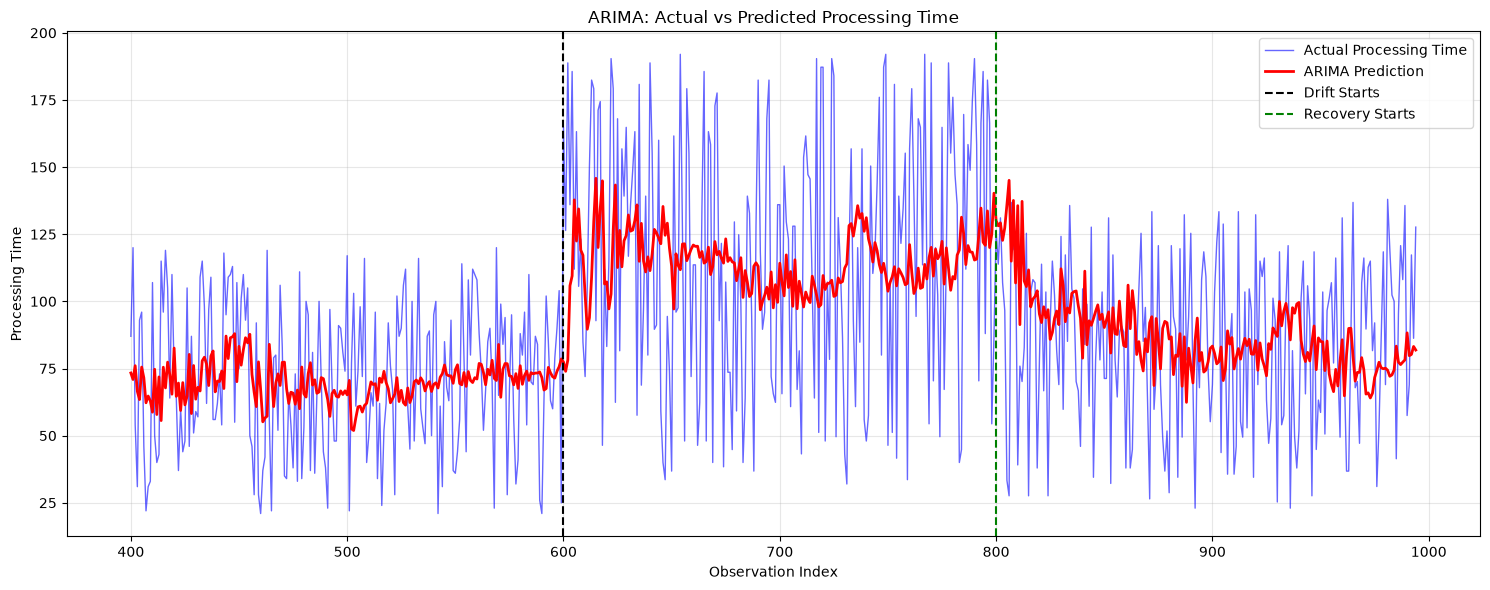

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("Results/ARIMA")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_arima_predictions(results_df):

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual Processing Time",
        color="blue",
        alpha=0.6,
        linewidth=1
    )

    ax.plot(
        results_df["idx"],
        results_df["predicted"],
        label="ARIMA Prediction",
        color="red",
        linewidth=2
    )

    ax.axvline(
        600,
        color="black",
        linestyle="--",
        label="Drift Starts"
    )

    ax.axvline(
        800,
        color="green",
        linestyle="--",
        label="Recovery Starts"
    )

    ax.set_title("ARIMA: Actual vs Predicted Processing Time")
    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Processing Time")

    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Save before displaying
    fig.savefig(
        OUTPUT_DIR / "arima_actual_vs_predicted.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_arima_predictions(arima_results_df)

In [6]:
# Save ARIMA predictions
arima_results_df.to_csv(
    OUTPUT_DIR / "arima_predictions.csv",
    index=False
)

# Save evaluation metrics
arima_metrics_df.to_csv(
    OUTPUT_DIR / "arima_metrics.csv"
)

print("ARIMA results saved successfully!")


ARIMA results saved successfully!
